<!-- <img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;"> -->
![MUML_header](MUML_header.svg)

### Optimization with autograd

Imagine you are a data scientist for a new logistics company. Your company needs to build a central distribution hub to serve several major cities. Your task is to find the single geographic point for the new hub that minimizes the total straight-line distance to all the cities it serves. However, not all the cities are equal: some are megacities while others are small towns. Our hub should probably be closer to the megacities.

 For a set of city coordinates c₁, c₂, ..., cₙ, we want to find the point p = (x, y) that minimizes the distance to all cities weighted by their population. It can be summarized in  the following function
$$dis(p)=\sum_i w_i * ||p - c_i||_2$$
where $||\ldots||_2$ is the standard Euclidean distance.
The derivative of this function is not simple to calculate by hand, especially for many cities. This is a perfect job for autograd.
Your task is, given a set of 2D coordinates for several cities and their population, to use PyTorch to find the optimal coordinates (x, y) for the distribution hub.

Location and population of the cities:
* City 1 - (0.0, 10.0) - 250,000 inhabitants
* City 2 - (1.0, 1.0) - 100,000 inhabitants
* City 3 - (12.0, 2.0) - 80,000 inhabitants
* City 4 - (15.0, 11.0) - 400,000 inhabitants
* City 5 - (8.0, 15.0) - 1,500 inhabitants
* City 6 - (5.0, 7.0) - 30,000 inhabitants


**Intuition**:
1. You should start by selecting a random point to locate the hub and calculating the function value at this point (without loops). 
2. With the gradient of the function at that point, can you know if the optimal point should have a bigger or a smaller value in x? And in y?
3. Move you solution a bit in those directions
4. Repeat the previous steps until you get a stable solution (or a given number of iterations)

**Questions**
1. What happens if you change the initial point to locate the hub? Try the following alternatives:
   * Random point
   * Centroid of the data
   * The exact location of one of the cities
   * A point outside the bounds of the data
2. What happens if you change the quantity you move your solution at each step (step 3 of intuition)? Try the following alternatives:
   * Very small quantity
   * Small quantity
   * Large quantity

Try using PyTorch for all the combinations from the above questions. With the best options, implement the optimization process using TensorFlow.
  
**Submission**
You have to create a short report (about two pages) evaluating the questions. It should contain graphs showing how the distance to the cities change and showing in the plane how the central distribution hub moves in between the cities. You also have to submit your code (not implemented with AI).

In [1]:
import matplotlib.pyplot as plt
import torch
import math
import random

In [2]:
cities = ["City 1", "City 2", "City 3", "City 4", "City 5", "City 6"]

x = [0, 1, 12, 15, 8, 5]
y = [10, 1, 2, 11, 15, 7]

inhabitants = [250000, 100000, 80000, 400000, 1500, 30000]

In [3]:
citySize = [i / 1000 for i in inhabitants]

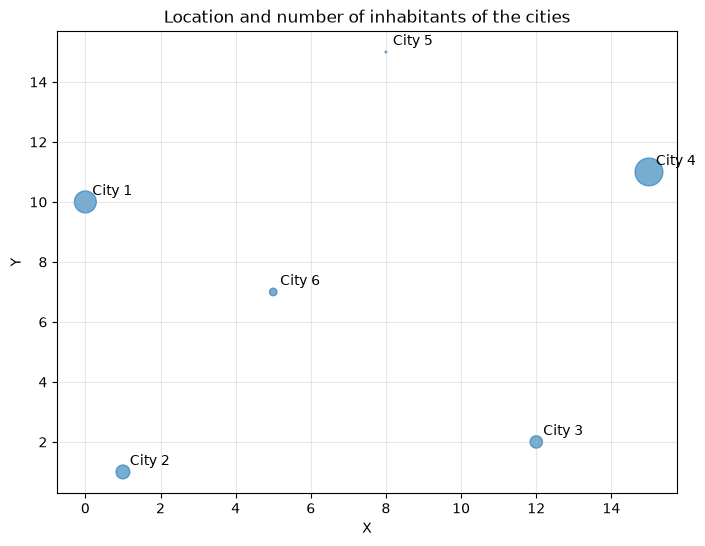

In [4]:
plt.figure(figsize=(8, 6))

plt.scatter(x, y, s=citySize, alpha=0.6)

for ciudad, xi, yi in zip(cities, x, y):
    plt.annotate(ciudad, (xi, yi), xytext=(5, 5),
                 textcoords="offset points")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Location and number of inhabitants of the cities")
plt.grid(True, alpha=0.3)

plt.show()

$$dis(p)=\sum_i w_i * ||p - c_i||_2$$
where $||\ldots||_2$ is the standard Euclidean distance.

In [5]:
c = torch.tensor([[0.0, 10.0], [1.0, 1.0], [12.0, 2.0], [15.0, 11.0], [8.0, 15.0], [5.0, 7.0]], requires_grad=True)
w = torch.tensor([250000, 100000, 80000, 400000, 1500, 30000])


In [6]:
def euclideanDistance(p1, p2):
    x1 = p1[0]
    y1 = p1[1]
    x2 = p2[0]
    y2 = p2[1]
    return torch.sqrt((x2-x1)**2+(y2-y1)**2)
def dis(p):
    return sum(w[i]*euclideanDistance(p, c[i]) for i in range(len(cities)))

In [7]:
result = dis([6, 8])
result

tensor(6968273.5000, grad_fn=<AddBackward0>)

In [8]:
#1. You should start by selecting a random point to locate the hub and calculating the function value at this point (without loops).
limit_x = max(x)
limit_y = max(y)
px = random.uniform(0, limit_x)
py = random.uniform(0, limit_y)
p = torch.tensor([px, py], requires_grad=True)

result_p = dis(p)
result_p

tensor(8966329., grad_fn=<AddBackward0>)

In [ ]:
# 2. With the gradient of the function at that point, can you know if the optimal point should have a bigger or a smaller value in x? And in y?
grad = 